# GAN-based OOD scoring on the ViT backbone — Group 9 OOD case study

Follow-up to `ViT_Model.ipynb`. That notebook fine-tunes a linear head on a frozen ViT and scores
out-of-distribution (OOD) images with MSP, Energy and Prototype distance on one fold (Mango held out).

This notebook adds a **GAN trained in the ViT's feature space** and uses its **discriminator as an
OOD scorer**, then tests it properly:

1. Features for every image are extracted **once** from the frozen ViT and cached, so a fold runs in about 20 seconds.
2. Each class gets a capture-day **train / validation / test** split; thresholds and checkpoints use
   validation only, and the main results are reported on test only.
3. All **6 leave-one-class-out folds** are run, over several seeds.
4. Three OOD test sets: the held-out fruit class, **IR-fusion** images of known fruit (modality shift),
   and an external **textures** set (DTD) standing in for foreign objects.
5. Baselines include **Mahalanobis** and **k-NN** distance, not only the weak Euclidean prototype distance.
6. GAN variants: plain GAN, **boundary** GAN (generator pushed towards class boundaries), and boundary GAN
   with **outlier exposure**, each against a control that isolates what the GAN itself adds. The GAN
   configuration is chosen on a validation-only design check, not on test results.
7. A **spoiled-produce stress test**: train on fresh fruit only, check whether rotten fruit of a known
   class is wrongly rejected as a foreign object.
8. A **patch-level** discriminator that gives a per-patch OOD heatmap (explainability).

In [1]:
import os

# hf_xet hangs on this network — force plain HTTPS before importing transformers (same as ViT_Model.ipynb).
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")

import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from PIL import Image
from scipy.stats import rankdata
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import DTD, Flowers102
from tqdm.auto import tqdm
from transformers import ViTModel, ViTImageProcessor

/home/adarssh/dev/NNDL/jupyter_lab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Config

In [2]:
NOTEBOOK_DIR = Path.cwd()
DATA_ROOT = next((d / "TR-6" for d in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents] if (d / "TR-6").exists()), NOTEBOOK_DIR / "TR-6")  # works from the repo root or experiments/gan/
CACHE_DIR = NOTEBOOK_DIR / "gan_ood_cache"        # extracted ViT features
EXTERNAL_DIR = NOTEBOOK_DIR / "external_ood"      # DTD + Flowers102 downloads
assert DATA_ROOT.exists(), f"TR-6 dataset not found at {DATA_ROOT}"
CACHE_DIR.mkdir(exist_ok=True)
EXTERNAL_DIR.mkdir(exist_ok=True)

CLASSES = ["Banana", "Carrot", "Guava", "Indian_Gooseberry", "Mango", "Tomato"]
PRETRAINED_CKPT = "google/vit-base-patch16-224-in21k"
IMAGE_SIZE = 224
EMBED_DIM = 768
PATCHES_PER_IMAGE = 16       # random patch tokens cached per image for the patch-level discriminator

SPLIT_SEED = 42
SEEDS = [3, 4, 5]            # head + GAN initialisation seeds (0-2 were used by the exploratory run)
N_BOOTSTRAP = 300

# Linear head: same recipe as ViT_Model.ipynb (frozen backbone, AdamW 1e-3, batch 32, 5 epochs).
HEAD_EPOCHS, HEAD_BATCH, HEAD_LR = 5, 32, 1e-3
KNN_K = 10

# Feature-space GAN. This configuration was selected on the validation-only design check further down.
GAN_STEPS = 1500
GAN_BATCH = 256
GAN_LR = 2e-4
NOISE_DIM = 128
G_HIDDEN = 1024
INSTANCE_NOISE = 0.1         # Gaussian noise added to every discriminator input (standardised units)
REAL_LABEL = 0.9             # one-sided label smoothing
BOUNDARY_BETA = 1.0          # weight of the push-to-class-boundary term in the generator loss
EVAL_EVERY = 100             # checkpoint interval (selection for outlier-exposure variants, monitoring)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Data root: {DATA_ROOT}\nDevice:    {DEVICE}")

pd.set_option("display.max_colwidth", 90)

# Chart styling: one palette for the whole notebook.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 110,
})

Data root: /home/adarssh/dev/NNDL/jupyter_lab/case_study/TR-6
Device:    cuda


## Data sources

| Source | Role | Used for training? |
|---|---|---|
| TR-6 sRGB (`Normal/<class>/sRGB_images`) | in-distribution data; held-out class is OOD test set 1 | known classes only |
| TR-6 IR-fusion (`Normal/<class>/IR_fusion_images`) | OOD test set 2 — same fruit, different modality | never |
| DTD textures (test split, 1,880 images) | OOD test set 3 — external "foreign objects" | never |
| Flowers102 (train 1,020 / val 1,020) | **auxiliary outliers**: outlier exposure + checkpoint selection | outlier-exposure variants only (including the patch-level discriminator) |

The auxiliary outliers and the three OOD test sets are disjoint datasets, so no test OOD data ever
influences training or model selection.

`Classified/<class>/Spoiled` holds the same sRGB files re-sorted, and is read only to label each
image as spoiled or fresh. Spoilage is a property of the capture day (asserted below).

In [3]:
def capture_day(path: Path) -> str:
    return path.name.split("_")[0]


def scan_tr6() -> pd.DataFrame:
    rows = []
    for cls in CLASSES:
        spoiled_names = {p.name for p in (DATA_ROOT / "Classified" / cls / "Spoiled" / "sRGB_images").glob("*.jpg")}
        srgb = sorted((DATA_ROOT / "Normal" / cls / "sRGB_images").glob("*.jpg"))
        spoiled_days = {capture_day(p) for p in srgb if p.name in spoiled_names}
        fresh_days = {capture_day(p) for p in srgb if p.name not in spoiled_names}
        assert spoiled_days.isdisjoint(fresh_days), f"{cls}: a capture day mixes spoiled and fresh images"
        for source, folder in [("srgb", "sRGB_images"), ("ir", "IR_fusion_images")]:
            for p in sorted((DATA_ROOT / "Normal" / cls / folder).glob("*.jpg")):
                day = capture_day(p)
                rows.append(dict(path=str(p.relative_to(NOTEBOOK_DIR)), source=source, cls=cls, day=day,
                                 spoiled=day in spoiled_days))
    return pd.DataFrame(rows)


def scan_external() -> pd.DataFrame:
    rows = []
    for split, tag in [("train", "aux_train"), ("val", "aux_val")]:
        ds = Flowers102(str(EXTERNAL_DIR), split=split, download=True)
        rows += [dict(path=str(Path(p).relative_to(NOTEBOOK_DIR)), source="flowers", split=tag) for p in ds._image_files]
    ds = DTD(str(EXTERNAL_DIR), split="test", partition=1, download=True)
    rows += [dict(path=str(Path(p).relative_to(NOTEBOOK_DIR)), source="dtd", split="ood_test") for p in ds._image_files]
    return pd.DataFrame(rows)


meta = pd.concat([scan_tr6(), scan_external()], ignore_index=True)
meta["spoiled"] = meta["spoiled"].eq(True)
print(meta.groupby("source").size().to_string())

source
dtd        1880
flowers    2040
ir         5492
srgb       5338


## Train / validation / test split by capture day

Filenames carry no specimen ID, so — as in `ViT_Model.ipynb` — the capture day is the grouping key and
a day never straddles two splits. Days are split roughly 60 / 20 / 20, **separately for fresh and
spoiled days** so every split sees both conditions where the class has enough days.

Known limitation: the same physical fruit is photographed on many days, so train and test still share
specimens. This makes in-distribution data look tighter than it would in deployment.

In [4]:
def assign_splits(days: list[str], rng: np.random.Generator) -> dict[str, str]:
    days = list(rng.permutation(sorted(days)))
    n = len(days)
    if n <= 2:
        n_test, n_val = n - 1, 0          # too few days for three splits: train first, then test
    else:
        n_test = n_val = max(1, round(0.2 * n))
    labels = ["test"] * n_test + ["val"] * n_val + ["train"] * (n - n_test - n_val)
    return dict(zip(days, labels))


rng = np.random.default_rng(SPLIT_SEED)
tr6 = meta["source"].isin(["srgb", "ir"])
for cls in CLASSES:
    for spoiled in (False, True):
        sel = (meta["source"] == "srgb") & (meta["cls"] == cls) & (meta["spoiled"] == spoiled)
        day_to_split = assign_splits(meta.loc[sel, "day"].unique().tolist(), rng)
        # IR-fusion images inherit the split of their capture day.
        rows = tr6 & (meta["cls"] == cls) & meta["day"].isin(day_to_split)
        meta.loc[rows, "split"] = meta.loc[rows, "day"].map(day_to_split)

srgb = meta[meta["source"] == "srgb"]
for cls, g in srgb.groupby("cls"):
    day_sets = [set(g.loc[g["split"] == s, "day"]) for s in ("train", "val", "test")]
    assert all(a.isdisjoint(b) for i, a in enumerate(day_sets) for b in day_sets[i + 1:]), f"{cls}: day leakage"
print("Capture-day isolation between train / val / test verified for every class.\n")

summary = srgb.groupby(["cls", "split"]).agg(images=("path", "size"), days=("day", "nunique"),
                                              spoiled_images=("spoiled", "sum")).unstack("split")
display(summary.reindex(columns=["train", "val", "test"], level=1))

Capture-day isolation between train / val / test verified for every class.



images            days          spoiled_images         
split              train  val test train val test          train val test
cls                                                                      
Banana               136   85  102     3   2    2             85  34   51
Carrot               305   51  102     6   1    2            254  51   51
Guava                306  102  102     6   2    2            204  51   51
Indian_Gooseberry    884  272  255    18   6    6            408  51   68
Mango                205  102   85     4   2    2             51  51   34
Tomato              1326  476  442    28  10   10             85  51   34

## Feature extraction (once, cached)

The backbone is frozen, so an image's pooled `[CLS]` embedding does not depend on which class is held
out. Every image is passed through the ViT once; all later experiments run on the cached 768-d vectors.
For sRGB and Flowers images, 16 random patch tokens per image are also kept for the patch-level
discriminator.

The TR-6 photos are 4000×3000 JPEGs; `Image.draft` decodes them at reduced size, which is far faster
and makes no practical difference after the resize to 224×224.

In [5]:
processor = ViTImageProcessor.from_pretrained(PRETRAINED_CKPT)
_vit = None


def get_vit() -> ViTModel:
    global _vit
    if _vit is None:
        _vit = ViTModel.from_pretrained(PRETRAINED_CKPT, add_pooling_layer=True).to(DEVICE).eval()
    return _vit


def load_rgb(path) -> Image.Image:
    image = Image.open(path)
    image.draft("RGB", (2 * IMAGE_SIZE, 2 * IMAGE_SIZE))
    return image.convert("RGB")


def to_pixels(image: Image.Image) -> torch.Tensor:
    return processor(images=image, return_tensors="pt")["pixel_values"][0]


class ImageFiles(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        return to_pixels(load_rgb(NOTEBOOK_DIR / self.paths[idx]))


@torch.no_grad()
def vit_forward(pixel_values: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Returns ([CLS] pooled embedding (B, 768), patch tokens (B, 196, 768))."""
    with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
        out = get_vit()(pixel_values=pixel_values.to(DEVICE))
    return out.pooler_output.float(), out.last_hidden_state[:, 1:].float()


def extract_features(paths, n_patches: int, desc: str) -> tuple[np.ndarray, np.ndarray]:
    loader = DataLoader(ImageFiles(paths), batch_size=64, shuffle=False, num_workers=min(8, os.cpu_count() or 2))
    gen = torch.Generator().manual_seed(SPLIT_SEED)
    cls_out, patch_out = [], []
    for pixel_values in tqdm(loader, desc=desc, leave=False):
        cls_emb, tokens = vit_forward(pixel_values)
        cls_out.append(cls_emb.cpu().numpy())
        if n_patches:
            pick = torch.rand(tokens.shape[:2], generator=gen).argsort(dim=1)[:, :n_patches].to(tokens.device)
            patch_out.append(tokens.gather(1, pick[:, :, None].expand(-1, -1, tokens.shape[2])).half().cpu().numpy())
    return np.concatenate(cls_out), (np.concatenate(patch_out) if n_patches else np.empty((0,)))


X = np.zeros((len(meta), EMBED_DIM), dtype=np.float32)
patch_tokens = {}  # source -> (n_images, PATCHES_PER_IMAGE, 768) float16, row order = meta order within the source
for source, g in meta.groupby("source"):
    n_patches = PATCHES_PER_IMAGE if source in ("srgb", "flowers") else 0
    cache = CACHE_DIR / f"{source}.npz"
    if cache.exists() and list(np.load(cache)["paths"]) == g["path"].tolist():
        data = np.load(cache)
        cls_emb, patches = data["cls"], data["patches"]
    else:
        start = time.time()
        cls_emb, patches = extract_features(g["path"], n_patches, desc=f"{source} features")
        np.savez(cache, paths=np.array(g["path"].tolist()), cls=cls_emb, patches=patches)
        print(f"{source:8s} extracted {len(g)} images in {time.time() - start:.0f}s")
    X[g.index.to_numpy()] = cls_emb
    if n_patches:
        patch_tokens[source] = patches
print(f"Feature matrix: {X.shape}")

X_all = torch.from_numpy(X).to(DEVICE)

Feature matrix: (14750, 768)


## OOD scorers

Every scorer is oriented so that **higher = more likely OOD**, and every scorer sees only the
training split of the known classes (plus auxiliary Flowers images where stated).

**Baselines**

- **MSP** and **Energy** — from the linear head, as in `ViT_Model.ipynb`.
- **Prototype** — Euclidean distance to the nearest class centroid.
- **Mahalanobis** — distance to the nearest class centroid under a shared covariance (Ledoit–Wolf shrinkage).
- **k-NN** — distance to the 10th nearest training embedding (L2-normalised).

In [6]:
def fit_head(X_train: torch.Tensor, y_train: torch.Tensor, n_classes: int, seed: int) -> nn.Linear:
    torch.manual_seed(seed)
    head = nn.Linear(EMBED_DIM, n_classes).to(DEVICE)
    optimizer = torch.optim.AdamW(head.parameters(), lr=HEAD_LR)
    counts = torch.bincount(y_train, minlength=n_classes).float()
    criterion = nn.CrossEntropyLoss(weight=len(y_train) / (n_classes * counts))
    for _ in range(HEAD_EPOCHS):
        for batch in torch.randperm(len(y_train), device=DEVICE).split(HEAD_BATCH):
            optimizer.zero_grad()
            criterion(head(X_train[batch]), y_train[batch]).backward()
            optimizer.step()
    return head.eval()


def msp_scorer(head):
    return lambda Z: 1.0 - head(Z).softmax(dim=1).max(dim=1).values


def energy_scorer(head):
    return lambda Z: -torch.logsumexp(head(Z), dim=1)


def class_means(X_train, y_train, n_classes):
    return torch.stack([X_train[y_train == c].mean(dim=0) for c in range(n_classes)])


def prototype_scorer(X_train, y_train, n_classes):
    means = class_means(X_train, y_train, n_classes)
    return lambda Z: torch.cdist(Z, means).min(dim=1).values


def mahalanobis_scorer(X_train, y_train, n_classes):
    means = class_means(X_train, y_train, n_classes)
    centred = (X_train - means[y_train]).cpu().numpy()
    covariance = LedoitWolf(assume_centered=True).fit(centred).covariance_
    precision = torch.from_numpy(np.linalg.inv(covariance)).float().to(DEVICE)

    def score(Z):
        diff = Z[:, None, :] - means[None, :, :]
        return torch.einsum("ncd,de,nce->nc", diff, precision, diff).min(dim=1).values.clamp_min(0).sqrt()

    return score


def knn_scorer(X_train, k: int = KNN_K):
    bank = F.normalize(X_train, dim=1)
    return lambda Z: torch.cdist(F.normalize(Z, dim=1), bank).topk(k, dim=1, largest=False).values[:, -1]

## Feature-space GAN

The generator maps noise to a fake 768-d embedding; the discriminator `D` learns to tell real
known-class embeddings from everything else. The OOD score is **−D(x)** (the negated real/fake logit).

Five variants share one training routine:

| Scorer | Discriminator's negatives | Purpose |
|---|---|---|
| `D: noise` | Gaussian noise | control — no generator at all |
| `GAN` | generator fakes | the plain GAN discriminator |
| `GAN boundary` | fakes from a generator that is also pushed to where the classifier is unsure | fakes sit between classes instead of copying them |
| `D: outliers` | real Flowers images | control — outlier exposure without a GAN |
| `GAN boundary + outliers` | boundary-GAN fakes **and** real Flowers images | the full model |

The first three use no outlier data and run for a fixed number of steps. The two outlier-exposure
variants pick their checkpoint by AUROC on ID-validation vs Flowers-validation.

Real batches are class-balanced (Tomato would otherwise dominate), embeddings are standardised with
training statistics, and small Gaussian noise on `D`'s inputs plus dropout keep it from memorising
the training set.

In [7]:
class Generator(nn.Module):
    def __init__(self, out_dim: int = EMBED_DIM, noise_dim: int = NOISE_DIM, hidden: int = G_HIDDEN,
                 batch_norm: bool = True):
        super().__init__()
        self.noise_dim = noise_dim
        norm = (lambda: [nn.BatchNorm1d(hidden)]) if batch_norm else (lambda: [])
        self.net = nn.Sequential(nn.Linear(noise_dim, hidden), *norm(), nn.LeakyReLU(0.2),
                                 nn.Linear(hidden, hidden), *norm(), nn.LeakyReLU(0.2),
                                 nn.Linear(hidden, out_dim))

    def sample(self, n: int):
        return self.net(torch.randn(n, self.noise_dim, device=DEVICE))


class Discriminator(nn.Module):
    def __init__(self, in_dim: int = EMBED_DIM):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, 512), nn.LeakyReLU(0.2), nn.Dropout(0.2),
                                 nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Dropout(0.2),
                                 nn.Linear(256, 1))

    def forward(self, x):
        return self.net(x).squeeze(1)


def auroc(neg_scores: np.ndarray, pos_scores: np.ndarray) -> float:
    """Probability that a positive (OOD) sample scores above a negative (ID) one."""
    ranks = rankdata(np.concatenate([neg_scores, pos_scores]))
    n_neg, n_pos = len(neg_scores), len(pos_scores)
    return float((ranks[n_neg:].sum() - n_pos * (n_pos + 1) / 2) / (n_neg * n_pos))


class GanScorer:
    """Trains a discriminator on real embeddings vs generator fakes / noise / real outliers."""

    def __init__(self, X_real, y_real, *, fakes: str | None, outliers=None, boundary_head=None,
                 select=None, monitor=None, generator: dict | None = None, seed: int = 0, steps: int = GAN_STEPS):
        """select / monitor: (ID embeddings, outlier embeddings). `select` keeps the checkpoint with the
        best AUROC on that pair; `monitor` only records the AUROC at every checkpoint."""
        assert fakes in ("gan", "noise", None)
        torch.manual_seed(seed)
        self.mean, self.std = X_real.mean(dim=0), X_real.std(dim=0) + 1e-6
        real_bank = self._standardise(X_real)
        outlier_bank = self._standardise(outliers) if outliers is not None else None
        dim = X_real.shape[1]

        self.D = Discriminator(dim).to(DEVICE)
        self.G = Generator(out_dim=dim, **(generator or {})).to(DEVICE) if fakes == "gan" else None
        opt_d = torch.optim.Adam(self.D.parameters(), lr=GAN_LR, betas=(0.5, 0.999))
        opt_g = torch.optim.Adam(self.G.parameters(), lr=GAN_LR, betas=(0.5, 0.999)) if self.G else None

        # Class-balanced sampling of real embeddings.
        sample_weight = (1.0 / torch.bincount(y_real).float())[y_real]
        noisy = lambda x: x + INSTANCE_NOISE * torch.randn_like(x)
        ones = torch.ones(GAN_BATCH, device=DEVICE)
        zeros = torch.zeros(GAN_BATCH, device=DEVICE)
        self.history, self.monitor_auroc, best_auroc, best_state = [], [], -1.0, None

        for step in range(1, steps + 1):
            self.D.train()
            real = real_bank[torch.multinomial(sample_weight, GAN_BATCH, replacement=True)]
            negatives = []
            if fakes == "gan":
                negatives.append(self.G.sample(GAN_BATCH).detach())
            elif fakes == "noise":
                negatives.append(torch.randn(GAN_BATCH, dim, device=DEVICE))
            if outlier_bank is not None:
                negatives.append(outlier_bank[torch.randint(len(outlier_bank), (GAN_BATCH,), device=DEVICE)])

            d_real = self.D(noisy(real))
            d_neg = [self.D(noisy(n)) for n in negatives]
            loss_d = F.binary_cross_entropy_with_logits(d_real, REAL_LABEL * ones) + \
                sum(F.binary_cross_entropy_with_logits(d, zeros) for d in d_neg) / len(d_neg)
            opt_d.zero_grad()
            loss_d.backward()
            opt_d.step()

            loss_g = torch.zeros(())
            if self.G:
                fake = self.G.sample(GAN_BATCH)
                loss_g = F.binary_cross_entropy_with_logits(self.D(noisy(fake)), ones)
                if boundary_head is not None:
                    # KL(uniform || classifier prediction): smallest when the fake sits between classes.
                    log_probs = boundary_head(fake * self.std + self.mean).log_softmax(dim=1)
                    loss_g = loss_g + BOUNDARY_BETA * (-log_probs.mean(dim=1) - np.log(log_probs.shape[1])).mean()
                opt_g.zero_grad()
                loss_g.backward()
                opt_g.step()

            if step % 25 == 0:
                self.history.append(dict(step=step, loss_d=loss_d.item(), loss_g=loss_g.item(),
                                         d_real=d_real.sigmoid().mean().item(),
                                         d_neg=d_neg[0].sigmoid().mean().item()))
            if monitor is not None and step % EVAL_EVERY == 0:
                self.monitor_auroc.append(auroc(self.score(monitor[0]).cpu().numpy(), self.score(monitor[1]).cpu().numpy()))
            if select is not None and step % EVAL_EVERY == 0:
                val_auroc = auroc(self.score(select[0]).cpu().numpy(), self.score(select[1]).cpu().numpy())
                if val_auroc > best_auroc:
                    best_auroc = val_auroc
                    best_state = {k: v.clone() for k, v in self.D.state_dict().items()}
        if best_state is not None:
            self.D.load_state_dict(best_state)
        self.D.eval()
        if self.G:
            self.G.eval()

    def _standardise(self, x):
        return (x - self.mean) / self.std

    @torch.no_grad()
    def score(self, Z):
        self.D.eval()
        return -self.D(self._standardise(Z))

    @torch.no_grad()
    def generate(self, n: int):
        """Fake embeddings in the original (un-standardised) feature space."""
        return self.G.sample(n) * self.std + self.mean

## Fitting all scorers

One helper fits every scorer on a given training set, so the design check and the real experiments
run exactly the same code.

In [8]:
BASELINES = ["MSP", "Energy", "Prototype", "Mahalanobis", "k-NN"]
GAN_FAMILY = ["D: noise", "GAN", "GAN boundary", "D: outliers", "GAN boundary + outliers"]
SCORERS = BASELINES + GAN_FAMILY
OOD_SETS = {"ood_class": "Held-out fruit class", "ood_ir": "IR-fusion (modality shift)", "ood_dtd": "DTD textures (external)"}


def rows_where(mask) -> torch.Tensor:
    return torch.from_numpy(np.flatnonzero(np.asarray(mask))).to(DEVICE)


@torch.no_grad()
def apply_scorer(fn, Z: torch.Tensor, batch: int = 2048) -> np.ndarray:
    return torch.cat([fn(chunk) for chunk in Z.split(batch)]).float().cpu().numpy()


def fit_scorers(X_train, y_train, n_classes: int, aux, select, seed: int, monitor=None):
    """Returns (linear head, {name: GanScorer}, {name: scoring function}) for all ten scorers."""
    head = fit_head(X_train, y_train, n_classes, seed)
    common = dict(seed=seed, monitor=monitor)
    gans = {
        "D: noise": GanScorer(X_train, y_train, fakes="noise", **common),
        "GAN": GanScorer(X_train, y_train, fakes="gan", **common),
        "GAN boundary": GanScorer(X_train, y_train, fakes="gan", boundary_head=head, **common),
        "D: outliers": GanScorer(X_train, y_train, fakes=None, outliers=aux, select=select, **common),
        "GAN boundary + outliers": GanScorer(X_train, y_train, fakes="gan", boundary_head=head, outliers=aux,
                                             select=select, **common),
    }
    scorers = {
        "MSP": msp_scorer(head),
        "Energy": energy_scorer(head),
        "Prototype": prototype_scorer(X_train, y_train, n_classes),
        "Mahalanobis": mahalanobis_scorer(X_train, y_train, n_classes),
        "k-NN": knn_scorer(X_train),
        **{name: gan.score for name, gan in gans.items()},
    }
    return head, gans, scorers

## Design check on validation data only

GAN discriminators are unstable, and Flowers images are so unlike fruit that they cannot tell a good
configuration from a bad one. This check uses a harder, test-free signal — an **inner
leave-one-class-out**: besides the fold's real held-out class, a second class is withheld and used as
a pseudo-OOD set. Scorers train on the remaining 4 classes and must separate the pseudo-OOD class from
ID validation images. No test day and no image of the real held-out class is touched.

For the GAN family the AUROC is tracked at every checkpoint: a large gap between the mean and the
minimum means the score depends heavily on when training happens to stop.

The first row is the configuration this notebook started with (a small generator without batch
normalisation); its weak result here is why the larger batch-normalised generator is used.

In [9]:
INNER_PAIRS = [(CLASSES[i], CLASSES[(i + 1) % len(CLASSES)]) for i in range(len(CLASSES))]  # (held-out, pseudo-OOD)
SMALL_GENERATOR = dict(noise_dim=64, hidden=512, batch_norm=False)

is_flowers = meta["source"] == "flowers"
AUX_TRAIN = X_all[rows_where(is_flowers & (meta["split"] == "aux_train"))]
AUX_VAL = X_all[rows_where(is_flowers & (meta["split"] == "aux_val"))]

design_rows = []
for held_out, pseudo_ood in tqdm(INNER_PAIRS, desc="design check"):
    known = [c for c in CLASSES if c not in (held_out, pseudo_ood)]
    pool = (meta["source"] == "srgb") & meta["cls"].isin(known)
    train_mask = pool & (meta["split"] == "train")
    X_train = X_all[rows_where(train_mask)]
    y_train = torch.tensor(meta.loc[train_mask, "cls"].map(known.index).to_numpy(), device=DEVICE)
    X_val = X_all[rows_where(pool & (meta["split"] == "val"))]
    X_pseudo = X_all[rows_where((meta["source"] == "srgb") & (meta["cls"] == pseudo_ood) & (meta["split"] != "test"))]

    head, gans, scorers = fit_scorers(X_train, y_train, len(known), AUX_TRAIN, (X_val, AUX_VAL), SEEDS[0],
                                      monitor=(X_val, X_pseudo))
    gans["GAN, small generator"] = GanScorer(X_train, y_train, fakes="gan", generator=SMALL_GENERATOR,
                                             seed=SEEDS[0], monitor=(X_val, X_pseudo))
    scorers["GAN, small generator"] = gans["GAN, small generator"].score
    for name, fn in scorers.items():
        checkpoints = gans[name].monitor_auroc if name in gans else [np.nan]
        design_rows.append(dict(scorer=name, final=auroc(apply_scorer(fn, X_val), apply_scorer(fn, X_pseudo)),
                                checkpoint_mean=np.mean(checkpoints), checkpoint_min=np.min(checkpoints)))

design = pd.DataFrame(design_rows).groupby("scorer").mean().reindex(["GAN, small generator"] + SCORERS)
print("Inner leave-one-class-out AUROC (ID validation vs pseudo-OOD class), mean over 6 class pairs")
display(design.round(3))

design check:   0%|          | 0/6 [00:00<?, ?it/s]

design check:  17%|█▋        | 1/6 [00:22<01:50, 22.10s/it]

design check:  33%|███▎      | 2/6 [00:41<01:22, 20.55s/it]

design check:  50%|█████     | 3/6 [01:01<01:00, 20.20s/it]

design check:  67%|██████▋   | 4/6 [01:20<00:39, 19.98s/it]

design check:  83%|████████▎ | 5/6 [01:40<00:19, 19.95s/it]

design check: 100%|██████████| 6/6 [02:01<00:00, 20.05s/it]

design check: 100%|██████████| 6/6 [02:01<00:00, 20.19s/it]

Inner leave-one-class-out AUROC (ID validation vs pseudo-OOD class), mean over 6 class pairs


,final,checkpoint_mean,checkpoint_min
scorer,,,
"GAN, small generator",0.878,0.881,0.538
MSP,0.999,NaN,NaN
Energy,0.999,NaN,NaN
Prototype,0.994,NaN,NaN
Mahalanobis,0.991,NaN,NaN
k-NN,0.986,NaN,NaN
D: noise,0.994,0.988,0.964
GAN,0.994,0.979,0.922
GAN boundary,0.995,0.998,0.994


## Experiment loop

One call = one leave-one-class-out fold with one seed. Two protocols:

- `standard` — train on the training days of the 5 known classes (fresh and spoiled).
- `fresh_only` — train on **fresh** training days only; spoiled images of known classes become an
  unseen-condition test set (used in the stress test further down).

In [10]:
def run_fold(held_out: str, seed: int, protocol: str = "standard", keep_models: bool = False) -> dict:
    known = [c for c in CLASSES if c != held_out]
    is_srgb, is_known = meta["source"] == "srgb", meta["cls"].isin(known)
    id_pool = is_srgb & is_known
    if protocol == "fresh_only":
        id_pool = id_pool & ~meta["spoiled"]

    sets = {
        "train": id_pool & (meta["split"] == "train"),
        "id_val": id_pool & (meta["split"] == "val"),
        "id_test": id_pool & (meta["split"] == "test"),
        "ood_class": is_srgb & (meta["cls"] == held_out),
        "ood_ir": (meta["source"] == "ir") & is_known & (meta["split"] == "test"),
        "ood_dtd": meta["source"] == "dtd",
        "aux_train": (meta["source"] == "flowers") & (meta["split"] == "aux_train"),
        "aux_val": (meta["source"] == "flowers") & (meta["split"] == "aux_val"),
    }
    if protocol == "fresh_only":
        sets["id_spoiled"] = is_srgb & is_known & meta["spoiled"]
    index = {name: rows_where(mask) for name, mask in sets.items()}

    X_train = X_all[index["train"]]
    y_train = torch.tensor(meta.loc[sets["train"], "cls"].map(known.index).to_numpy(), device=DEVICE)
    assert len(torch.unique(y_train)) == len(known)

    head, gans, scorers = fit_scorers(X_train, y_train, len(known), X_all[index["aux_train"]],
                                      (X_all[index["id_val"]], X_all[index["aux_val"]]), seed)

    eval_sets = [name for name in sets if name not in ("train", "aux_train")]
    result = {
        "scores": {s: {name: apply_scorer(fn, X_all[index[name]]) for name in eval_sets} for s, fn in scorers.items()},
        "rows": {name: index[name].cpu().numpy() for name in eval_sets},
        "id_test_accuracy": (head(X_all[index["id_test"]]).argmax(dim=1).cpu().numpy()
                             == meta.loc[sets["id_test"], "cls"].map(known.index).to_numpy()).mean(),
    }
    if keep_models:
        result.update(head=head, gans=gans, known=known, index=index)
    return result


start = time.time()
runs = {}
for held_out in tqdm(CLASSES, desc="folds"):
    for seed in SEEDS:
        runs[(held_out, seed)] = run_fold(held_out, seed)
print(f"{len(runs)} runs ({len(CLASSES)} folds × {len(SEEDS)} seeds) in {time.time() - start:.0f}s")

folds:   0%|          | 0/6 [00:00<?, ?it/s]

folds:  17%|█▋        | 1/6 [00:49<04:09, 49.84s/it]

folds:  33%|███▎      | 2/6 [01:40<03:20, 50.11s/it]

folds:  50%|█████     | 3/6 [02:30<02:30, 50.10s/it]

folds:  67%|██████▋   | 4/6 [03:19<01:39, 49.75s/it]

folds:  83%|████████▎ | 5/6 [04:09<00:49, 49.99s/it]

folds: 100%|██████████| 6/6 [04:59<00:00, 49.79s/it]

folds: 100%|██████████| 6/6 [04:59<00:00, 49.88s/it]

18 runs (6 folds × 3 seeds) in 299s


## Results

Metrics, all computed on **test** data (ID test days vs each OOD test set):

- **AUROC** — chance that an OOD image scores above an ID image (1.0 = perfect, 0.5 = chance).
- **AUPR** — average precision with OOD as the positive class.
- **FPR@95** — share of OOD images still accepted when the threshold accepts 95% of ID test images (lower is better).
- **OOD accepted @ val threshold** — the same quantity, with the threshold set on ID *validation*
  scores, as it would be in deployment.

`val AUROC` is ID-validation vs Flowers-validation — the only number used for checkpoint selection.

In [11]:
def fpr_at_95(id_scores, ood_scores) -> float:
    return float((ood_scores <= np.quantile(id_scores, 0.95)).mean())


records = []
for (held_out, seed), run in runs.items():
    for scorer, s in run["scores"].items():
        val_threshold = np.quantile(s["id_val"], 0.95)
        for ood_set in OOD_SETS:
            records.append(dict(
                fold=held_out, seed=seed, scorer=scorer, ood_set=ood_set,
                auroc=auroc(s["id_test"], s[ood_set]),
                aupr=average_precision_score(np.r_[np.zeros(len(s["id_test"])), np.ones(len(s[ood_set]))],
                                             np.r_[s["id_test"], s[ood_set]]),
                fpr95=fpr_at_95(s["id_test"], s[ood_set]),
                ood_accepted=float((s[ood_set] <= val_threshold).mean()),
                id_rejected=float((s["id_test"] > val_threshold).mean()),
                val_auroc=auroc(s["id_val"], s["aux_val"]),
            ))
results = pd.DataFrame(records)

accuracy = pd.Series({k: r["id_test_accuracy"] for k, r in runs.items()})
print(f"Known-class accuracy on ID test (control, GAN never touches the classifier): "
      f"mean {accuracy.mean():.4f}, min {accuracy.min():.4f}")

# Average over folds within each seed, then mean ± std over seeds.
METRICS = ["auroc", "aupr", "fpr95", "ood_accepted"]
per_seed = results.groupby(["scorer", "ood_set", "seed"])[METRICS].mean()
mean, std = per_seed.groupby(["scorer", "ood_set"]).mean(), per_seed.groupby(["scorer", "ood_set"]).std()
table = (mean.round(3).astype(str) + " ± " + std.fillna(0).round(3).astype(str)).unstack("ood_set")
table = table.reindex(SCORERS).reindex(columns=list(OOD_SETS), level=1).rename(columns=OOD_SETS, level=1)
for metric in METRICS:
    print(f"\n{metric.upper()} — mean over 6 folds, ± std over {len(SEEDS)} seeds")
    display(table[metric])

val_table = results.groupby(["scorer", "seed"])[["val_auroc", "id_rejected"]].mean().groupby("scorer").mean()
print("\nValidation AUROC (ID val vs Flowers val) and ID-test rejection rate at the validation threshold (target 0.05)")
display(val_table.reindex(SCORERS).round(3))

Known-class accuracy on ID test (control, GAN never touches the classifier): mean 1.0000, min 1.0000

AUROC — mean over 6 folds, ± std over 3 seeds


ood_set,Held-out fruit class,IR-fusion (modality shift),DTD textures (external)
scorer,,,
MSP,0.988 ± 0.001,0.998 ± 0.001,1.0 ± 0.0
Energy,0.987 ± 0.002,0.999 ± 0.001,1.0 ± 0.0
Prototype,0.985 ± 0.0,1.0 ± 0.0,1.0 ± 0.0
Mahalanobis,0.986 ± 0.0,1.0 ± 0.0,1.0 ± 0.0
k-NN,0.983 ± 0.0,1.0 ± 0.0,1.0 ± 0.0
D: noise,0.989 ± 0.002,1.0 ± 0.0,1.0 ± 0.0
GAN,0.963 ± 0.022,0.997 ± 0.002,0.996 ± 0.003
GAN boundary,0.995 ± 0.001,0.997 ± 0.0,1.0 ± 0.0
D: outliers,0.993 ± 0.001,1.0 ± 0.0,1.0 ± 0.0



AUPR — mean over 6 folds, ± std over 3 seeds


ood_set,Held-out fruit class,IR-fusion (modality shift),DTD textures (external)
scorer,,,
MSP,0.99 ± 0.001,0.998 ± 0.001,1.0 ± 0.0
Energy,0.99 ± 0.002,0.999 ± 0.001,1.0 ± 0.0
Prototype,0.963 ± 0.0,1.0 ± 0.0,1.0 ± 0.0
Mahalanobis,0.973 ± 0.0,1.0 ± 0.0,1.0 ± 0.0
k-NN,0.97 ± 0.0,1.0 ± 0.0,1.0 ± 0.0
D: noise,0.973 ± 0.004,1.0 ± 0.0,1.0 ± 0.0
GAN,0.952 ± 0.02,0.996 ± 0.003,0.997 ± 0.002
GAN boundary,0.992 ± 0.001,0.997 ± 0.001,1.0 ± 0.0
D: outliers,0.994 ± 0.0,1.0 ± 0.0,1.0 ± 0.0



FPR95 — mean over 6 folds, ± std over 3 seeds


ood_set,Held-out fruit class,IR-fusion (modality shift),DTD textures (external)
scorer,,,
MSP,0.049 ± 0.004,0.004 ± 0.003,0.0 ± 0.0
Energy,0.055 ± 0.007,0.004 ± 0.003,0.0 ± 0.0
Prototype,0.055 ± 0.0,0.001 ± 0.0,0.0 ± 0.0
Mahalanobis,0.076 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
k-NN,0.1 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
D: noise,0.083 ± 0.001,0.0 ± 0.0,0.0 ± 0.0
GAN,0.137 ± 0.075,0.008 ± 0.004,0.008 ± 0.01
GAN boundary,0.024 ± 0.007,0.014 ± 0.002,0.0 ± 0.0
D: outliers,0.029 ± 0.002,0.0 ± 0.0,0.0 ± 0.0



OOD_ACCEPTED — mean over 6 folds, ± std over 3 seeds


ood_set,Held-out fruit class,IR-fusion (modality shift),DTD textures (external)
scorer,,,
MSP,0.027 ± 0.002,0.001 ± 0.001,0.0 ± 0.0
Energy,0.036 ± 0.005,0.002 ± 0.002,0.0 ± 0.0
Prototype,0.037 ± 0.0,0.001 ± 0.0,0.0 ± 0.0
Mahalanobis,0.06 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
k-NN,0.099 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
D: noise,0.046 ± 0.011,0.0 ± 0.0,0.0 ± 0.0
GAN,0.102 ± 0.07,0.006 ± 0.004,0.006 ± 0.007
GAN boundary,0.003 ± 0.002,0.004 ± 0.003,0.0 ± 0.0
D: outliers,0.034 ± 0.002,0.0 ± 0.0,0.0 ± 0.0



Validation AUROC (ID val vs Flowers val) and ID-test rejection rate at the validation threshold (target 0.05)


,val_auroc,id_rejected
scorer,,
MSP,1.000,0.083
Energy,1.000,0.083
Prototype,1.000,0.082
Mahalanobis,1.000,0.097
k-NN,1.000,0.069
D: noise,1.000,0.091
GAN,0.998,0.064
GAN boundary,1.000,0.105
D: outliers,1.000,0.036


### Uncertainty: cluster bootstrap over capture days

The 17 photos taken of a fruit on one day are not independent, so resampling individual images would
give intervals that are too narrow. Here whole capture days are resampled (DTD images individually),
with the **same resample applied to every scorer** so that differences between scorers are paired.
Each replicate is averaged over the seeds, so the intervals describe the same seed-averaged numbers
as the tables above.

Note that each panel has its own x-axis range: on the IR-fusion and DTD panels the whole axis spans less than 0.01 AUROC.

bootstrap:   0%|          | 0/6 [00:00<?, ?it/s]

bootstrap:  17%|█▋        | 1/6 [00:03<00:19,  3.91s/it]

bootstrap:  33%|███▎      | 2/6 [00:07<00:15,  3.94s/it]

bootstrap:  50%|█████     | 3/6 [00:11<00:11,  3.94s/it]

bootstrap:  67%|██████▋   | 4/6 [00:15<00:08,  4.01s/it]

bootstrap:  83%|████████▎ | 5/6 [00:19<00:03,  3.98s/it]

bootstrap: 100%|██████████| 6/6 [00:24<00:00,  4.08s/it]

bootstrap: 100%|██████████| 6/6 [00:24<00:00,  4.02s/it]

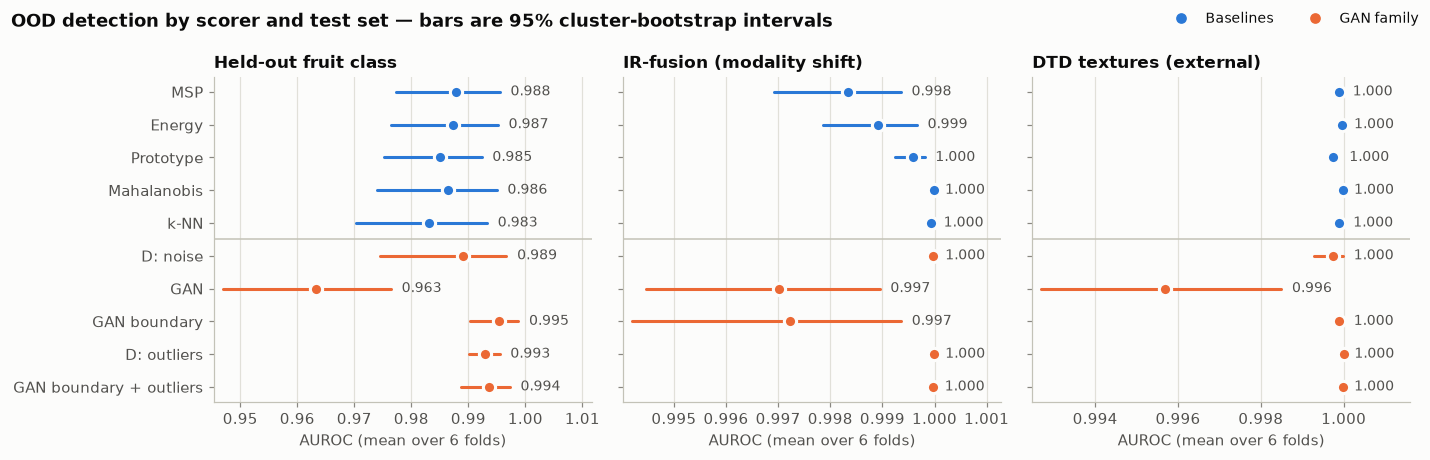

In [12]:
def cluster_members(rows: np.ndarray) -> list[np.ndarray]:
    """Positions (within `rows`) of each cluster: a class-day for TR-6 images, a single image otherwise."""
    m = meta.iloc[rows]
    keys = np.where(m["source"].isin(["srgb", "ir"]), m["cls"].astype(str) + "_" + m["day"].astype(str), m["path"])
    codes = pd.factorize(keys)[0]
    return [np.flatnonzero(codes == c) for c in range(codes.max() + 1)]


def resample(members: list[np.ndarray], rng) -> np.ndarray:
    return np.concatenate([members[c] for c in rng.integers(len(members), size=len(members))])


boot_rng = np.random.default_rng(SPLIT_SEED)
# boot[scorer, ood_set, fold, replicate], each entry averaged over seeds
boot = np.zeros((len(SCORERS), len(OOD_SETS), len(CLASSES), N_BOOTSTRAP))
for f, held_out in enumerate(tqdm(CLASSES, desc="bootstrap")):
    fold_runs = [runs[(held_out, seed)] for seed in SEEDS]
    id_members = cluster_members(fold_runs[0]["rows"]["id_test"])   # rows are identical across seeds
    for o, ood_set in enumerate(OOD_SETS):
        ood_members = cluster_members(fold_runs[0]["rows"][ood_set])
        for b in range(N_BOOTSTRAP):
            id_pick, ood_pick = resample(id_members, boot_rng), resample(ood_members, boot_rng)
            for s, scorer in enumerate(SCORERS):
                boot[s, o, f, b] = np.mean([auroc(run["scores"][scorer]["id_test"][id_pick],
                                                  run["scores"][scorer][ood_set][ood_pick]) for run in fold_runs])

fold_mean = boot.mean(axis=2)                                   # [scorer, ood_set, replicate]
ci_low, ci_high = np.percentile(fold_mean, [2.5, 97.5], axis=2)
point = mean["auroc"].unstack("ood_set").reindex(SCORERS)[list(OOD_SETS)].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
y = np.arange(len(SCORERS))[::-1]
colors = [BLUE] * len(BASELINES) + [ORANGE] * len(GAN_FAMILY)
for o, (ax, title) in enumerate(zip(axes, OOD_SETS.values())):
    for s in range(len(SCORERS)):
        ax.plot([ci_low[s, o], ci_high[s, o]], [y[s], y[s]], color=colors[s], lw=2, solid_capstyle="round")
        ax.plot(point[s, o], y[s], "o", color=colors[s], ms=8, mec=SURFACE, mew=2)
        ax.annotate(f"{point[s, o]:.3f}", (max(ci_high[s, o], point[s, o]), y[s]), xytext=(7, 0),
                    textcoords="offset points", va="center", fontsize=9, color=INK_2)
    ax.set_title(title)
    ax.set_xlabel("AUROC (mean over 6 folds)")
    ax.set_yticks(y, SCORERS)
    ax.grid(axis="y", visible=False)
    left = min(ci_low[:, o].min(), point[:, o].min())
    ax.set_xlim(left - 0.03 * (1 - left), 1 + 0.22 * (1 - left))
    ax.axhline(len(GAN_FAMILY) - 0.5, color=AXIS, lw=1)
axes[0].plot([], [], "o", color=BLUE, label="Baselines")
axes[0].plot([], [], "o", color=ORANGE, label="GAN family")
fig.legend(loc="upper right", ncols=2, fontsize=9)
fig.suptitle("OOD detection by scorer and test set — bars are 95% cluster-bootstrap intervals",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### Paired comparisons

Difference in fold-mean AUROC between pairs of scorers, with a 95% interval from the paired bootstrap.
An interval that excludes 0 means the difference is larger than the sampling noise in the test images.

In [13]:
def paired_difference(a: str, b: str) -> list[str]:
    diff = fold_mean[SCORERS.index(a)] - fold_mean[SCORERS.index(b)]          # [ood_set, replicate]
    delta = point[SCORERS.index(a)] - point[SCORERS.index(b)]
    lo, hi = np.percentile(diff, [2.5, 97.5], axis=1)
    return [f"{d:+.3f}  [{l:+.3f}, {h:+.3f}]" for d, l, h in zip(delta, lo, hi)]


comparisons = [
    ("GAN", "D: noise", "Does a plain generator beat Gaussian noise as the negative class?"),
    ("GAN boundary", "GAN", "Does pushing fakes to class boundaries help?"),
    ("GAN boundary", "D: noise", "Does the boundary GAN beat the no-generator control?"),
    ("GAN boundary", "Energy", "Boundary GAN vs the best classifier-based baseline"),
    ("GAN boundary", "Mahalanobis", "Boundary GAN vs the best distance-based baseline"),
    ("GAN boundary + outliers", "D: outliers", "Does the GAN add anything on top of outlier exposure?"),
    ("GAN boundary + outliers", "GAN boundary", "Does outlier exposure help the boundary GAN?"),
    ("GAN boundary + outliers", "Energy", "Full model vs Energy"),
]
paired = pd.DataFrame([paired_difference(a, b) for a, b, _ in comparisons], columns=list(OOD_SETS.values()),
                      index=pd.MultiIndex.from_tuples([(f"{a}  −  {b}", q) for a, b, q in comparisons],
                                                      names=["AUROC difference", "question"]))
display(paired)

,,Held-out fruit class,IR-fusion (modality shift),DTD textures (external)
AUROC difference,question,,,
GAN − D: noise,Does a plain generator beat Gaussian noise as the negative class?,"-0.026 [-0.039, -0.013]","-0.003 [-0.005, -0.001]","-0.004 [-0.007, -0.001]"
GAN boundary − GAN,Does pushing fakes to class boundaries help?,"+0.032 [+0.021, +0.044]","+0.000 [-0.002, +0.002]","+0.004 [+0.001, +0.007]"
GAN boundary − D: noise,Does the boundary GAN beat the no-generator control?,"+0.006 [+0.000, +0.016]","-0.003 [-0.006, -0.001]","+0.000 [-0.000, +0.001]"
GAN boundary − Energy,Boundary GAN vs the best classifier-based baseline,"+0.008 [+0.002, +0.015]","-0.002 [-0.004, -0.000]","-0.000 [-0.000, -0.000]"
GAN boundary − Mahalanobis,Boundary GAN vs the best distance-based baseline,"+0.009 [+0.002, +0.020]","-0.003 [-0.006, -0.001]","-0.000 [-0.000, +0.000]"
GAN boundary + outliers − D: outliers,Does the GAN add anything on top of outlier exposure?,"+0.001 [-0.004, +0.004]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]"
GAN boundary + outliers − GAN boundary,Does outlier exposure help the boundary GAN?,"-0.002 [-0.004, +0.001]","+0.003 [+0.001, +0.006]","+0.000 [-0.000, +0.000]"
GAN boundary + outliers − Energy,Full model vs Energy,"+0.006 [+0.002, +0.012]","+0.001 [+0.000, +0.002]","+0.000 [-0.000, +0.000]"


### Per-fold view

Which held-out class is hard, and for which scorer. Averages can hide a scorer that fails on one fold.

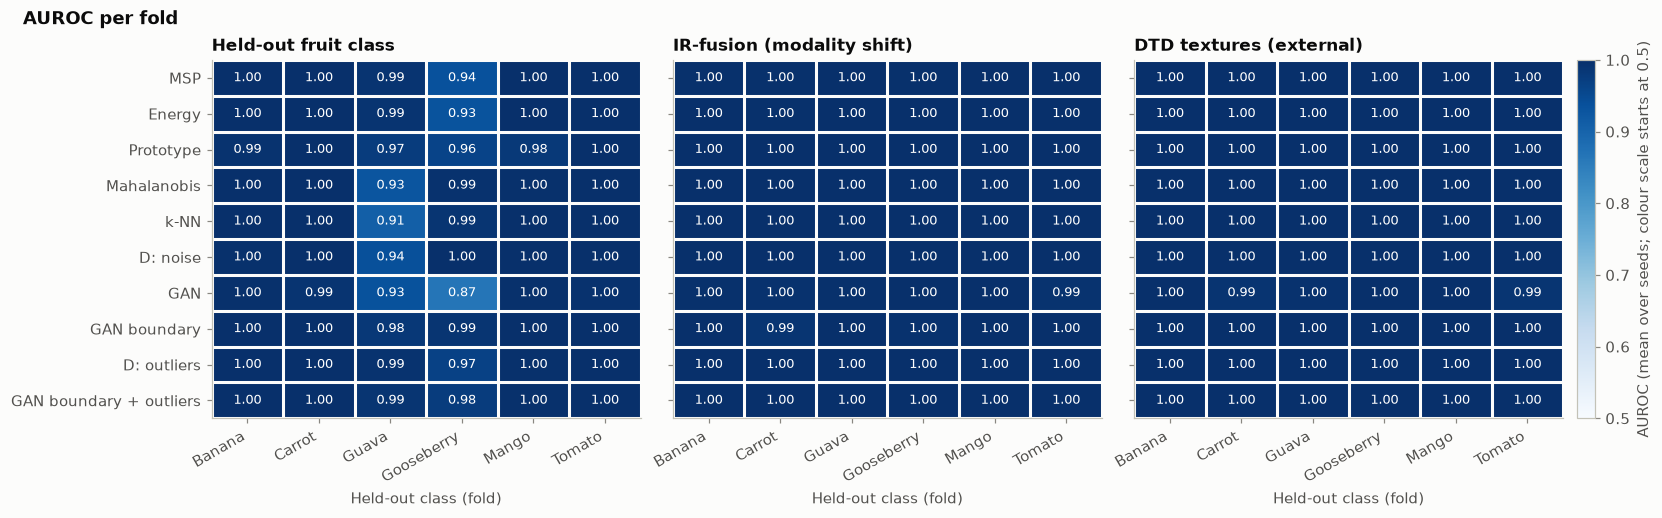

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True, layout="constrained")
for ax, (ood_set, title) in zip(axes, OOD_SETS.items()):
    grid = results[results["ood_set"] == ood_set].pivot_table(index="scorer", columns="fold", values="auroc")
    grid = grid.reindex(SCORERS)[CLASSES]
    im = ax.imshow(grid.to_numpy(), cmap="Blues", vmin=0.5, vmax=1.0, aspect="auto")
    for (i, j), value in np.ndenumerate(grid.to_numpy()):
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8.5, color="white" if value > 0.85 else INK)
    ax.set_xticks(range(len(CLASSES)), [c.replace("Indian_Gooseberry", "Gooseberry") for c in CLASSES], rotation=30, ha="right")
    ax.set_yticks(range(len(SCORERS)), SCORERS)
    ax.set_xlabel("Held-out class (fold)")
    ax.set_title(title)
    ax.grid(False)
    ax.set_xticks(np.arange(-0.5, len(CLASSES)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(SCORERS)), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="minor", length=0)
fig.colorbar(im, ax=axes, label="AUROC (mean over seeds; colour scale starts at 0.5)", fraction=0.02, pad=0.01)
fig.suptitle("AUROC per fold", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.show()

## Sanity checks on the GAN (fold: Mango held out)

- **Training curves** — `D`'s mean output on real vs fake embeddings. A healthy GAN keeps them apart
  but not saturated at 1 and 0; if they collapse together the discriminator has stopped learning anything.
- **PCA of the feature space** — where the generated embeddings sit relative to real ID and real OOD ones.

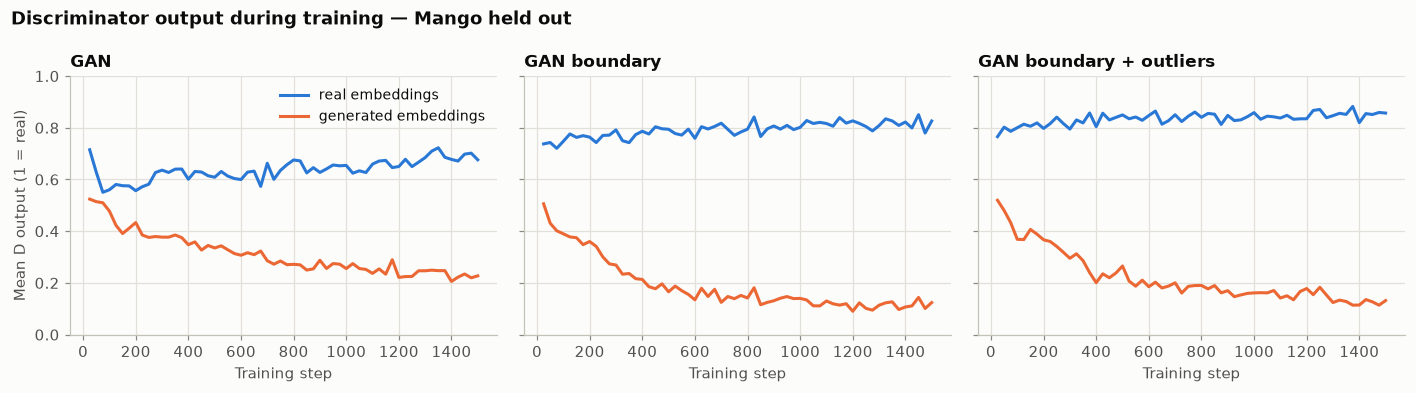

In [15]:
DEMO_FOLD = "Mango"
demo = run_fold(DEMO_FOLD, SEEDS[0], keep_models=True)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, name in zip(axes, ["GAN", "GAN boundary", "GAN boundary + outliers"]):
    history = pd.DataFrame(demo["gans"][name].history)
    ax.plot(history["step"], history["d_real"], color=BLUE, label="real embeddings")
    ax.plot(history["step"], history["d_neg"], color=ORANGE, label="generated embeddings")
    ax.set_title(name)
    ax.set_xlabel("Training step")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Mean D output (1 = real)")
axes[0].legend(fontsize=9)
fig.suptitle(f"Discriminator output during training — {DEMO_FOLD} held out", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

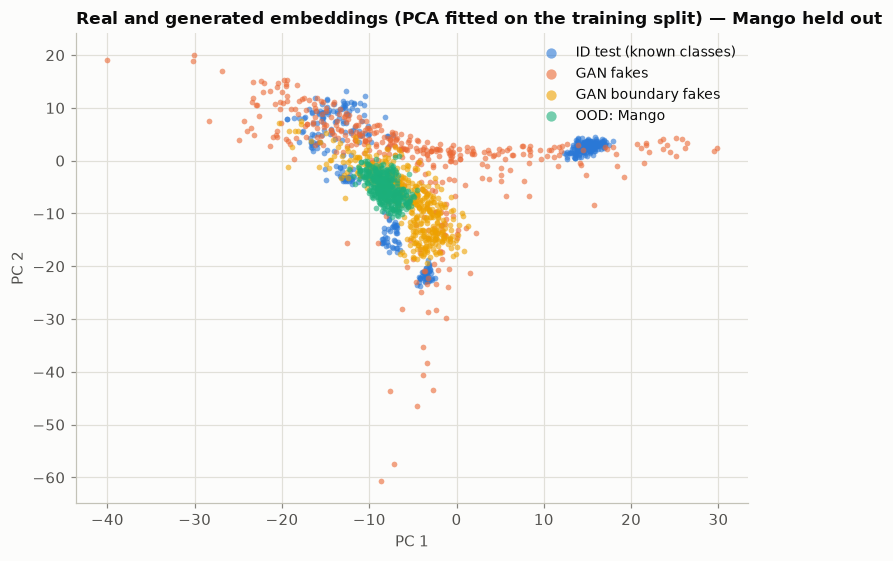

In [16]:
idx = demo["index"]
pca_rng = np.random.default_rng(0)
take = lambda t, n=400: t[torch.from_numpy(pca_rng.permutation(len(t))[:n]).to(t.device)]
groups = {
    "ID test (known classes)": (take(X_all[idx["id_test"]]), BLUE),
    "GAN fakes": (demo["gans"]["GAN"].generate(400), ORANGE),
    "GAN boundary fakes": (demo["gans"]["GAN boundary"].generate(400), YELLOW),
    f"OOD: {DEMO_FOLD}": (take(X_all[idx["ood_class"]]), AQUA),
}
reference = demo["gans"]["GAN"]
pca = PCA(n_components=2).fit(reference._standardise(X_all[idx["train"]]).cpu().numpy())
fig, ax = plt.subplots(figsize=(7, 5.2))
for label, (emb, color) in groups.items():
    xy = pca.transform(reference._standardise(emb).cpu().numpy())
    ax.scatter(xy[:, 0], xy[:, 1], s=14, color=color, alpha=0.6, linewidths=0, label=label)
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_title(f"Real and generated embeddings (PCA fitted on the training split) — {DEMO_FOLD} held out")
ax.legend(fontsize=9, markerscale=1.8)
plt.tight_layout()
plt.show()

### Score distributions (same fold)

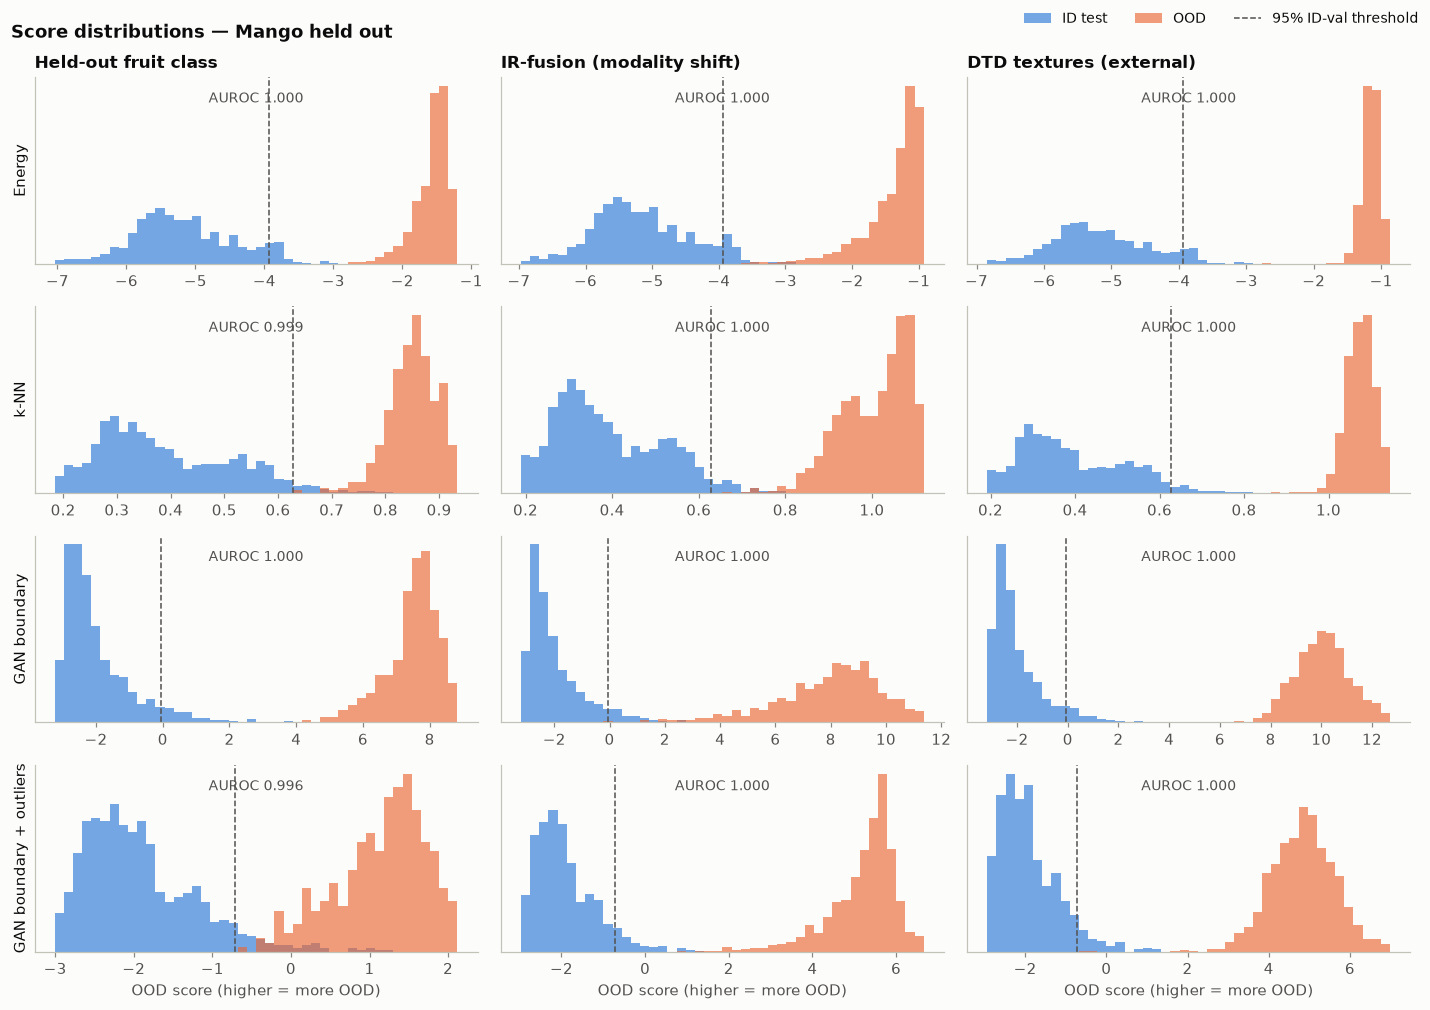

In [17]:
SHOW = ["Energy", "k-NN", "GAN boundary", "GAN boundary + outliers"]
fig, axes = plt.subplots(len(SHOW), len(OOD_SETS), figsize=(13, 2.3 * len(SHOW)))
for r, scorer in enumerate(SHOW):
    s = demo["scores"][scorer]
    threshold = np.quantile(s["id_val"], 0.95)
    for c, (ood_set, title) in enumerate(OOD_SETS.items()):
        ax = axes[r, c]
        lo, hi = np.percentile(np.r_[s["id_test"], s[ood_set]], [0.5, 99.5])
        bins = np.linspace(lo, hi, 45)
        ax.hist(s["id_test"], bins=bins, density=True, color=BLUE, alpha=0.65, label="ID test")
        ax.hist(s[ood_set], bins=bins, density=True, color=ORANGE, alpha=0.65, label="OOD")
        ax.axvline(threshold, color=INK_2, ls="--", lw=1, label="95% ID-val threshold")
        ax.set_yticks([])
        ax.grid(False)
        ax.set_title(title if r == 0 else "")
        ax.text(0.5, 0.92, f"AUROC {auroc(s['id_test'], s[ood_set]):.3f}", transform=ax.transAxes,
                ha="center", va="top", fontsize=9, color=INK_2)
    axes[r, 0].set_ylabel(scorer, fontsize=10, color=INK)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncols=3, fontsize=9)
fig.suptitle(f"Score distributions — {DEMO_FOLD} held out", x=0.01, ha="left", fontsize=12, fontweight="bold")
for ax in axes[-1]:
    ax.set_xlabel("OOD score (higher = more OOD)")
plt.tight_layout()
plt.show()

## Stress test: is spoiled produce rejected as a foreign object?

A grading line must reject foreign objects, not rotten tomatoes. Here every scorer is fitted on
**fresh** training days only, so spoiled fruit of a known class is a condition it has never seen.

- **Spoiled rejected** — share of spoiled known-class images flagged as OOD at the threshold that
  accepts 95% of fresh validation images. The matching rate for fresh test images is the reference.
- **Spoiled vs foreign AUROC** — can the scorer still tell spoiled known fruit (should be accepted)
  from the held-out class (should be rejected)?

fresh-only folds:   0%|          | 0/6 [00:00<?, ?it/s]

fresh-only folds:  17%|█▋        | 1/6 [00:16<01:20, 16.20s/it]

fresh-only folds:  33%|███▎      | 2/6 [00:33<01:07, 16.80s/it]

fresh-only folds:  50%|█████     | 3/6 [01:05<01:10, 23.61s/it]

fresh-only folds:  67%|██████▋   | 4/6 [01:38<00:55, 27.53s/it]

fresh-only folds:  83%|████████▎ | 5/6 [02:12<00:29, 29.88s/it]

fresh-only folds: 100%|██████████| 6/6 [02:46<00:00, 31.15s/it]

fresh-only folds: 100%|██████████| 6/6 [02:46<00:00, 27.72s/it]

,fresh_rejected,spoiled_rejected,fresh_vs_foreign_auroc,spoiled_vs_foreign_auroc
scorer,,,,
MSP,0.097,0.544,0.998,0.949
Energy,0.115,0.594,0.998,0.917
Prototype,0.065,0.511,0.995,0.821
Mahalanobis,0.117,0.632,0.993,0.761
k-NN,0.085,0.542,0.995,0.854
D: noise,0.124,0.663,0.994,0.859
GAN,0.098,0.361,0.992,0.913
GAN boundary,0.136,0.598,0.995,0.837
D: outliers,0.036,0.450,0.989,0.864


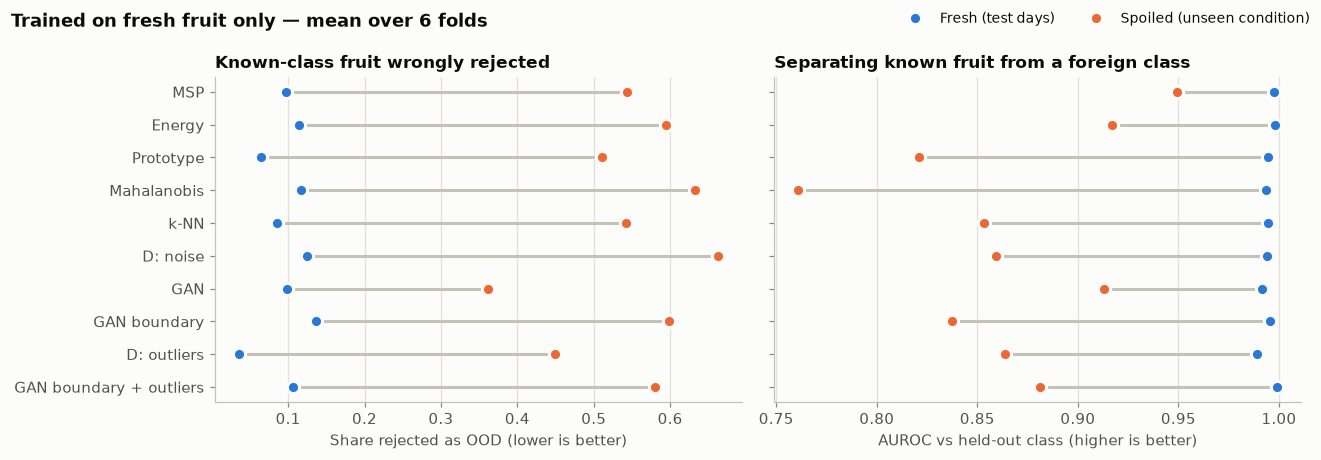

In [18]:
stress_records = []
for held_out in tqdm(CLASSES, desc="fresh-only folds"):
    run = run_fold(held_out, SEEDS[0], protocol="fresh_only")
    for scorer, s in run["scores"].items():
        threshold = np.quantile(s["id_val"], 0.95)
        stress_records.append(dict(
            fold=held_out, scorer=scorer,
            fresh_rejected=float((s["id_test"] > threshold).mean()),
            spoiled_rejected=float((s["id_spoiled"] > threshold).mean()),
            fresh_vs_foreign_auroc=auroc(s["id_test"], s["ood_class"]),
            spoiled_vs_foreign_auroc=auroc(s["id_spoiled"], s["ood_class"]),
        ))
stress = pd.DataFrame(stress_records)
stress_mean = stress.groupby("scorer").mean(numeric_only=True).reindex(SCORERS)
display(stress_mean.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
y = np.arange(len(SCORERS))[::-1]
panels = [("fresh_rejected", "spoiled_rejected", "Share rejected as OOD (lower is better)", "Known-class fruit wrongly rejected"),
          ("fresh_vs_foreign_auroc", "spoiled_vs_foreign_auroc", "AUROC vs held-out class (higher is better)", "Separating known fruit from a foreign class")]
for ax, (fresh_col, spoiled_col, xlabel, title) in zip(axes, panels):
    for s, scorer in enumerate(SCORERS):
        a, b = stress_mean.loc[scorer, fresh_col], stress_mean.loc[scorer, spoiled_col]
        ax.plot([a, b], [y[s], y[s]], color=AXIS, lw=2, zorder=1)
        ax.plot(a, y[s], "o", color=BLUE, ms=8, mec=SURFACE, mew=2, label="Fresh (test days)" if s == 0 else None)
        ax.plot(b, y[s], "o", color=ORANGE, ms=8, mec=SURFACE, mew=2, label="Spoiled (unseen condition)" if s == 0 else None)
    ax.set_yticks(y, SCORERS)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncols=2, fontsize=9)
fig.suptitle("Trained on fresh fruit only — mean over 6 folds", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## Patch-level discriminator: where is the foreign object?

The same GAN code is trained on individual **patch tokens** instead of the pooled `[CLS]` vector:
real = patches from known-class training images, negatives = generator fakes and Flowers patches.
(The boundary term needs a classifier on the tokens, which patches do not have, so the plain generator is used.) Scoring all 196 patches of an image gives a 14×14 OOD map, a second explainability
signal alongside the attention rollout planned in `ViT_Model.ipynb`.

Fold: Mango held out. Two tests follow — heatmaps on real images, and a pointing test on composites
where a foreign crop is pasted onto an in-distribution photo.

Patch discriminator trained on 47,312 real patch tokens.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 8416.55it/s]

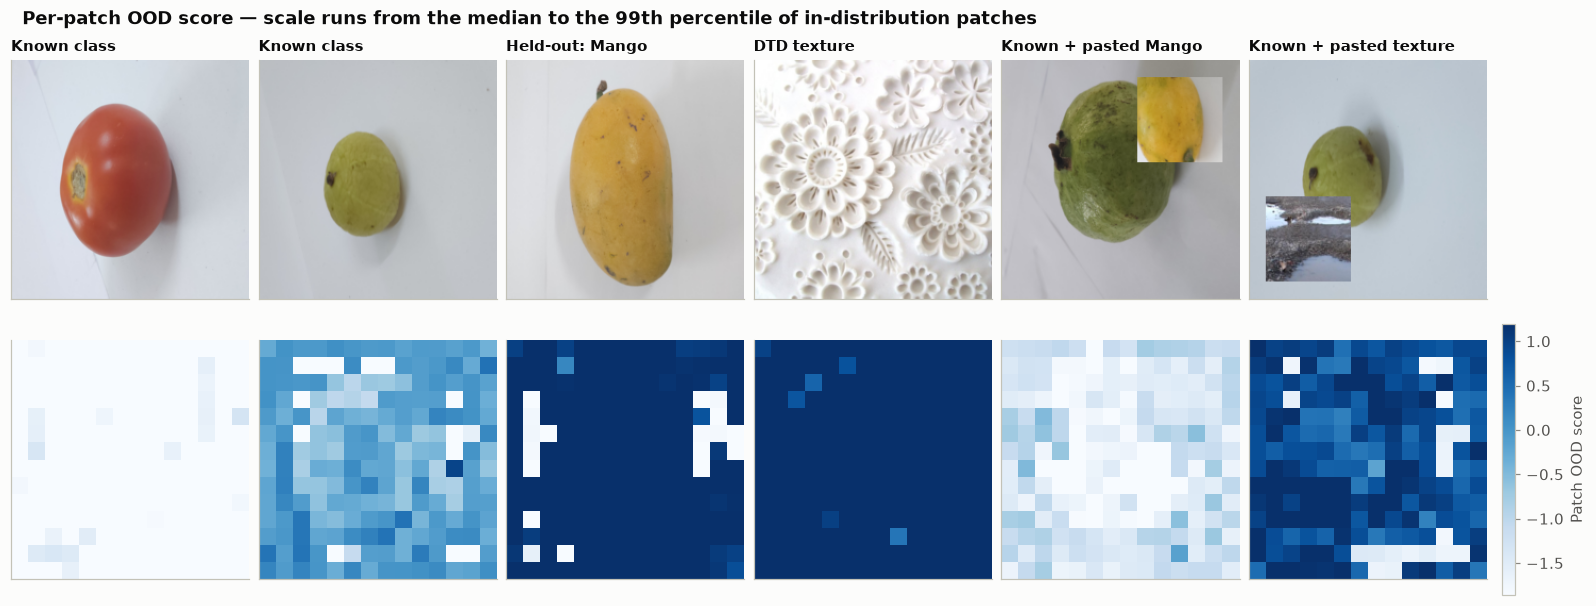

In [19]:
known = demo["known"]
srgb_rows = meta.index[meta["source"] == "srgb"].to_numpy()          # patch_tokens["srgb"] row order
flower_rows = meta.index[meta["source"] == "flowers"].to_numpy()


def patch_bank(source: str, mask) -> torch.Tensor:
    rows = srgb_rows if source == "srgb" else flower_rows
    keep = np.asarray(mask)[rows]
    return torch.from_numpy(patch_tokens[source][keep].astype(np.float32)).reshape(-1, EMBED_DIM).to(DEVICE)


srgb_known = (meta["source"] == "srgb") & meta["cls"].isin(known)
train_mask = srgb_known & (meta["split"] == "train")
patch_train = patch_bank("srgb", train_mask)
patch_labels = torch.tensor(np.repeat(meta.loc[train_mask, "cls"].map(known.index).to_numpy(), PATCHES_PER_IMAGE), device=DEVICE)
patch_gan = GanScorer(
    patch_train, patch_labels, fakes="gan", seed=SEEDS[0],
    outliers=patch_bank("flowers", meta["split"] == "aux_train"),
    select=(patch_bank("srgb", srgb_known & (meta["split"] == "val")), patch_bank("flowers", meta["split"] == "aux_val")),
)
print(f"Patch discriminator trained on {len(patch_train):,} real patch tokens.")


@torch.no_grad()
def patch_map(images: list[Image.Image]) -> np.ndarray:
    """(n, 14, 14) patch OOD scores for a list of PIL images."""
    _, tokens = vit_forward(torch.stack([to_pixels(im) for im in images]))
    return patch_gan.score(tokens.reshape(-1, EMBED_DIM)).reshape(len(images), 14, 14).cpu().numpy()


def load_square(path) -> Image.Image:
    return load_rgb(NOTEBOOK_DIR / path).resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)


def paste_foreign(base: Image.Image, foreign: Image.Image, corner: tuple[int, int], size: int = 80) -> Image.Image:
    """Pastes the centre of `foreign` onto `base`; corner and size are multiples of the 16-px patch grid."""
    c = IMAGE_SIZE // 2
    crop = foreign.crop((c - 64, c - 64, c + 64, c + 64)).resize((size, size), Image.BILINEAR)
    out = base.copy()
    out.paste(crop, corner)
    return out


demo_rng = np.random.default_rng(1)
pick = lambda mask, n: meta.loc[mask, "path"].sample(n, random_state=int(demo_rng.integers(1 << 30))).tolist()
id_test_mask = srgb_known & (meta["split"] == "test")
held_out_mask = (meta["source"] == "srgb") & (meta["cls"] == DEMO_FOLD)
dtd_mask = meta["source"] == "dtd"

id_images = [load_square(p) for p in pick(id_test_mask, 4)]
examples = {
    "Known class": id_images[0], "Known class ": id_images[1],
    f"Held-out: {DEMO_FOLD}": load_square(pick(held_out_mask, 1)[0]),
    "DTD texture": load_square(pick(dtd_mask, 1)[0]),
    f"Known + pasted {DEMO_FOLD}": paste_foreign(id_images[2], load_square(pick(held_out_mask, 1)[0]), (128, 16)),
    "Known + pasted texture": paste_foreign(id_images[3], load_square(pick(dtd_mask, 1)[0]), (16, 128)),
}
maps = patch_map(list(examples.values()))
id_reference = patch_gan.score(patch_bank("srgb", srgb_known & (meta["split"] == "val"))).cpu().numpy()
vmin, vmax = np.percentile(id_reference, [50, 99])

fig, axes = plt.subplots(2, len(examples), figsize=(2.4 * len(examples), 5.4), layout="constrained")
for col, ((title, image), score_map) in enumerate(zip(examples.items(), maps)):
    axes[0, col].imshow(image)
    axes[0, col].set_title(title.strip(), fontsize=9.5)
    im = axes[1, col].imshow(score_map, cmap="Blues", vmin=vmin, vmax=vmax)
    for ax in axes[:, col]:
        ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
fig.colorbar(im, ax=axes[1, :], label="Patch OOD score", fraction=0.012, pad=0.01)
fig.suptitle("Per-patch OOD score — scale runs from the median to the 99th percentile of in-distribution patches",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.show()

### Pointing test on composites

200 in-distribution test photos each get an 80×80 foreign crop (5×5 patches) pasted in a random corner.

- **Pointing accuracy** — is the single highest-scoring patch inside the pasted region? Chance = 25/196 ≈ 12.8%.
- **Patch AUROC** — do pasted patches score above the rest of the same image?
- **Image AUROC** — clean vs composite images, using the mean of the 10 highest patch scores per image.

In [20]:
N_COMPOSITES = 200
CORNERS = [(16, 16), (128, 16), (16, 128), (128, 128)]
top10_mean = lambda m: np.sort(m.reshape(len(m), -1), axis=1)[:, -10:].mean(axis=1)


def pointing_test(foreign_mask, label: str) -> dict:
    rng = np.random.default_rng(7)
    base_paths = meta.loc[id_test_mask, "path"].sample(N_COMPOSITES, random_state=7, replace=True).tolist()
    foreign_paths = meta.loc[foreign_mask, "path"].sample(N_COMPOSITES, random_state=7, replace=True).tolist()
    hits, patch_aurocs, clean_scores, composite_scores = [], [], [], []
    for start in tqdm(range(0, N_COMPOSITES, 50), desc=label, leave=False):
        bases = [load_square(p) for p in base_paths[start:start + 50]]
        corners = [CORNERS[i] for i in rng.integers(len(CORNERS), size=len(bases))]
        composites = [paste_foreign(b, load_square(f), c) for b, f, c in zip(bases, foreign_paths[start:start + 50], corners)]
        clean_maps, composite_maps = patch_map(bases), patch_map(composites)
        for score_map, (x0, y0) in zip(composite_maps, corners):
            inside = np.zeros((14, 14), dtype=bool)
            inside[y0 // 16:y0 // 16 + 5, x0 // 16:x0 // 16 + 5] = True
            hits.append(inside.flat[score_map.argmax()])
            patch_aurocs.append(auroc(score_map[~inside], score_map[inside]))
        clean_scores.append(top10_mean(clean_maps))
        composite_scores.append(top10_mean(composite_maps))
    return {"pasted object": label, "pointing accuracy": np.mean(hits), "patch AUROC": np.mean(patch_aurocs),
            "image AUROC (clean vs composite)": auroc(np.concatenate(clean_scores), np.concatenate(composite_scores))}


pointing = pd.DataFrame([pointing_test(held_out_mask, f"{DEMO_FOLD} (held-out class)"),
                         pointing_test(dtd_mask, "DTD texture")]).set_index("pasted object")
print(f"Chance pointing accuracy: {25 / 196:.3f}")
display(pointing.round(3))

Mango (held-out class):   0%|          | 0/4 [00:00<?, ?it/s]

Mango (held-out class):  25%|██▌       | 1/4 [00:02<00:08,  2.78s/it]

Mango (held-out class):  50%|█████     | 2/4 [00:05<00:05,  2.71s/it]

Mango (held-out class):  75%|███████▌  | 3/4 [00:08<00:02,  2.70s/it]

Mango (held-out class): 100%|██████████| 4/4 [00:10<00:00,  2.73s/it]

DTD texture:   0%|          | 0/4 [00:00<?, ?it/s]

... (2 outputs left out)

DTD texture:  75%|███████▌  | 3/4 [00:04<00:01,  1.57s/it]

DTD texture: 100%|██████████| 4/4 [00:06<00:00,  1.59s/it]

Chance pointing accuracy: 0.128


,pointing accuracy,patch AUROC,image AUROC (clean vs composite)
pasted object,,,
Mango (held-out class),0.890,0.898,0.929
DTD texture,0.855,0.934,0.897


## Acceptance tests

The scorer under test is `GAN boundary`: the outlier-free GAN variant selected on the validation-only
design check. `Energy` is the reference implementation and `D: noise` the no-generator control.

The criteria below were fixed after an exploratory run with seeds 0–2 and **before** this run with
seeds 3–5. The test images are the same in both runs, so this guards against picking favourable
seeds, not against reusing the test set.

| ID | Technique | Criterion |
|---|---|---|
| T1a | Back-to-back testing against a reference scorer | held-out-class AUROC ≥ AUROC(Energy) − 0.01 |
| T1b | Back-to-back, per fold | worst held-out class AUROC ≥ 0.95 |
| T1c | Back-to-back, operating point | FPR@95 on the held-out class ≤ 0.10 |
| T2a | Control (ablation) test | AUROC gain over `D: noise` has a 95% interval above 0 |
| T2b | Oracle sanity check on far-OOD data | AUROC ≥ 0.99 on IR-fusion and on DTD |
| T3a | Non-regression | known-class accuracy on ID test ≥ 0.99 |
| T3b | False-alarm budget | ID test images rejected at the validation threshold ≤ 0.10 (nominal 0.05) |
| T4 | Repeatability | std of held-out-class AUROC over seeds ≤ 0.01 |
| T5 | Robustness (metamorphic: spoiling a known fruit must not make it foreign) | spoiled rejection ≤ 2 × fresh rejection, fresh-only training |
| T6 | Explainability | pointing accuracy ≥ 0.50 for both pasted objects (chance 0.128) |

T6 tests the patch-level discriminator, which uses the plain generator plus Flowers patches, not `GAN boundary`.

In [21]:
import json

PRIMARY, REFERENCE, CONTROL = "GAN boundary", "Energy", "D: noise"
metric = lambda scorer, ood_set, name="auroc": float(mean.loc[(scorer, ood_set), name])
primary = results[results["scorer"] == PRIMARY]
fold_auroc = primary[primary["ood_set"] == "ood_class"].groupby("fold")["auroc"].mean()
class_col = list(OOD_SETS).index("ood_class")
control_gain = fold_mean[SCORERS.index(PRIMARY), class_col] - fold_mean[SCORERS.index(CONTROL), class_col]
control_low, control_high = np.percentile(control_gain, [2.5, 97.5])
seed_std = float(std.loc[(PRIMARY, "ood_class"), "auroc"])
id_rejected = float(primary["id_rejected"].mean())
fresh_rejected, spoiled_rejected = stress_mean.loc[PRIMARY, ["fresh_rejected", "spoiled_rejected"]]
far = {name: metric(PRIMARY, name) for name in ("ood_ir", "ood_dtd")}
point_acc = pointing["pointing accuracy"]

a, e, c = metric(PRIMARY, "ood_class"), metric(REFERENCE, "ood_class"), metric(CONTROL, "ood_class")
checks = [
    ("T1a", "Back-to-back vs Energy (AUROC)", f"{a:.3f} ≥ {e:.3f} − 0.01 = {e - 0.01:.3f}", a >= e - 0.01),
    ("T1b", "Worst fold AUROC", f"{fold_auroc.min():.3f} ({fold_auroc.idxmin()}) ≥ 0.95", fold_auroc.min() >= 0.95),
    ("T1c", "FPR@95, held-out class", f"{metric(PRIMARY, 'ood_class', 'fpr95'):.3f} ≤ 0.10", metric(PRIMARY, "ood_class", "fpr95") <= 0.10),
    ("T2a", "Gain over no-generator control", f"{a - c:+.3f}, 95% interval [{control_low:+.3f}, {control_high:+.3f}] above 0", control_low > 0),
    ("T2b", "Far-OOD sanity (AUROC)", f"IR-fusion {far['ood_ir']:.3f}, DTD {far['ood_dtd']:.3f} ≥ 0.99", min(far.values()) >= 0.99),
    ("T3a", "Known-class accuracy", f"{accuracy.mean():.4f} ≥ 0.99", accuracy.mean() >= 0.99),
    ("T3b", "ID test rejected at validation threshold", f"{id_rejected:.3f} ≤ 0.10", id_rejected <= 0.10),
    ("T4", "Seed std of AUROC", f"{seed_std:.4f} ≤ 0.01", seed_std <= 0.01),
    ("T5", "Spoiled vs fresh rejection", f"{spoiled_rejected:.3f} ≤ 2 × {fresh_rejected:.3f} = {2 * fresh_rejected:.3f}", spoiled_rejected <= 2 * fresh_rejected),
    ("T6", "Pointing accuracy", f"{point_acc.min():.3f} (worst of {', '.join(f'{v:.3f}' for v in point_acc)}) ≥ 0.50", point_acc.min() >= 0.50),
]
test_report = pd.DataFrame(checks, columns=["ID", "Test", "Measured", "passed"])
test_report["Result"] = np.where(test_report.pop("passed"), "PASS", "FAIL")
print(f"{(test_report['Result'] == 'PASS').sum()} of {len(test_report)} acceptance tests pass.")
display(test_report.set_index("ID"))

fold_table = results[results["ood_set"] == "ood_class"].pivot_table(index="scorer", columns="fold", values="auroc").reindex(SCORERS)[CLASSES]
summary_table = {m: mean[m].unstack("ood_set").reindex(SCORERS)[list(OOD_SETS)] for m in METRICS}
with open(NOTEBOOK_DIR / "gan_vit_test_results.json", "w") as f:
    json.dump({
        "seeds": SEEDS, "primary": PRIMARY, "tests": test_report.to_dict("records"),
        "mean": {m: t.round(6).to_dict("index") for m, t in summary_table.items()},
        "seed_std_auroc": std["auroc"].unstack("ood_set").reindex(SCORERS).round(6).to_dict("index"),
        "auroc_ci": {s: {o: [round(float(ci_low[i, j]), 6), round(float(ci_high[i, j]), 6)] for j, o in enumerate(OOD_SETS)} for i, s in enumerate(SCORERS)},
        "fold_auroc": fold_table.round(6).to_dict("index"),
        "operating_point": val_table.reindex(SCORERS).round(6).to_dict("index"),
        "paired": paired.reset_index().to_dict("records"),
        "design_check": design.round(6).reset_index().to_dict("records"),
        "stress": stress_mean.round(6).to_dict("index"),
        "pointing": pointing.round(6).to_dict("index"),
        "split": {c: {s: {"images": int(((srgb["cls"] == c) & (srgb["split"] == s)).sum()),
                          "days": int(srgb.loc[(srgb["cls"] == c) & (srgb["split"] == s), "day"].nunique())} for s in ("train", "val", "test")} for c in CLASSES},
        "known_class_accuracy": float(accuracy.mean()),
    }, f, indent=2)

8 of 10 acceptance tests pass.


,Test,Measured,Result
ID,,,
T1a,Back-to-back vs Energy (AUROC),0.995 ≥ 0.987 − 0.01 = 0.977,PASS
T1b,Worst fold AUROC,0.984 (Guava) ≥ 0.95,PASS
T1c,"FPR@95, held-out class",0.024 ≤ 0.10,PASS
T2a,Gain over no-generator control,"+0.006, 95% interval [+0.000, +0.016] above 0",PASS
T2b,Far-OOD sanity (AUROC),"IR-fusion 0.997, DTD 1.000 ≥ 0.99",PASS
T3a,Known-class accuracy,1.0000 ≥ 0.99,PASS
T3b,ID test rejected at validation threshold,0.105 ≤ 0.10,FAIL
T4,Seed std of AUROC,0.0009 ≤ 0.01,PASS
T5,Spoiled vs fresh rejection,0.598 ≤ 2 × 0.136 = 0.273,FAIL


## Conclusions

Numbers below are from the saved run of this notebook (6 folds, seeds 3–5). Where the earlier
exploratory run (seeds 0–2) differed in a way that matters, both are given.

**Acceptance tests: 8 of 10 pass.** The two failures are the false-alarm budget (T3b: 10.5% of
in-distribution test images rejected against a 10% limit) and robustness to spoiled produce (T5).

**1. The boundary GAN's discriminator is a competitive OOD scorer; the plain GAN's is not.**
On the held-out fruit class, mean AUROC is 0.995 for `GAN boundary`, against 0.986–0.988 for MSP,
Energy and Mahalanobis, 0.985 for Prototype and 0.983 for k-NN. The plain `GAN` reaches only 0.963 and
is worse than the no-generator control `D: noise` (0.989).

**2. Its lead over the best baseline is small and borderline.**
`GAN boundary − Energy` is +0.008 with a 95% interval of [+0.002, +0.015] in this run, and was +0.006
[−0.002, +0.012] in the exploratory run, so the interval excludes 0 in one run and not in the other.
The lead over the noise control is +0.006 [+0.000, +0.016]. The boundary term is what makes the GAN
work: +0.032 [+0.021, +0.044] over the plain GAN.

**3. Outlier exposure neither needs nor benefits from the GAN.**
`D: outliers` (no generator) scores 0.993 and the full model 0.994; the difference is +0.001 [−0.004, +0.004].

**4. At a deployed threshold the boundary GAN trades false alarms for misses.**
With the threshold set on validation data it lets through 0.3% of held-out-class images (MSP 2.7%,
Energy 3.6%) but rejects 10.5% of in-distribution test images (MSP and Energy 8.3%; target 5%).
At a matched 95% ID acceptance rate its FPR@95 is 0.024 against 0.049–0.055.

**5. The IR-fusion and DTD test sets turned out to be easy.**
Every scorer reaches AUROC ≥ 0.995 on both. They confirm nothing is broken, but they cannot rank the
scorers; the held-out fruit class is the only test here that does, and only the Guava and Indian
Gooseberry folds are hard.

**6. Spoiled produce is a real problem for every scorer.**
Trained on fresh fruit only, the scorers reject 36–66% of spoiled known-class images as OOD (4–14% on
fresh test images). The boundary GAN rejects 60%. The plain GAN rejects fewest (36%). Separating spoiled
known fruit from a foreign class drops to AUROC 0.76–0.95, with MSP best (0.949). Training data must
cover the spoiled condition; no scorer here fixes that on its own.

**7. The patch-level discriminator localises pasted objects well above chance.**
The highest-scoring patch falls inside the pasted region in 89% (Mango crop) and 86% (texture crop) of
composites, against 12.8% by chance. The maps are coarse, though: a foreign patch raises the score of
other patches in the same image, because final-layer ViT tokens carry global context.

### Limitations

- **Shared specimens.** The same fruit is photographed across days, so train and test are not
  independent. This flatters every scorer.
- **Test-set exposure during development.** An earlier configuration (small generator, plain GAN with
  outliers) was run once on the test sets before the design check existed, and the acceptance criteria
  were written after the exploratory run with seeds 0–2. The reported run uses fresh seeds, but the
  same test images, so the results are not perfectly blind.
- **Checkpoint selection for the outlier-exposure variants is weak.** Flowers validation AUROC is 1.000
  for almost every scorer, so it cannot tell checkpoints apart (ties go to the earliest one).
- **GAN instability.** In the design check the plain GAN's worst checkpoint averages 0.922 validation
  AUROC against 0.994 at its final step; the boundary variant's worst checkpoint is 0.994, which is
  the main practical reason to prefer it.
- **Single fold for explainability.** The patch-level results and sanity-check figures use the Mango fold only,
  and the patch-level discriminator is a different GAN variant from the one tested in T1–T5.
- **One seed for the stress test.**
